# ADAR1 Zα – Z-DNA vs B-DNA: MDS analysis and visualisations
Inputs: `data/<stem>.prmtop` + `data/<stem>.xtc` for every model in `config.MODELS`. Intermediate tables are written once to
`output/csv/` and re-used (set `config.FORCE_RECOMPUTE = True` to recompute); figures go to `output/figures/`.

### Settings and imports

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

import config
from common import (cached_csv, compute_rmsd, compute_rmsf, draw_colorbar, draw_dna_group_legend, draw_heatmap, heatmap_annotations,
                    highlight_tick_labels, load_universe, plot_jaccard_heatmap, save_figure, setup_environment)
from contact_analysis import (align_residues, atom_lifetime_matrix, contact_cooccurrence, dna_group_order, residue_contact_matrix,
                              residue_lifetime_matrix, run_contact_and_lifetime_analysis)
from foldx_utils import run_foldx_analysis
from pyrosetta_utils import run_interface_analysis

setup_environment()
MODELS = config.MODELS

### RMSD Analysis

INFO: The attribute(s) masses, types have already been read from the topology file. The guesser will only guess empty values for this attribute, if any exists. To overwrite it by completely guessed values, you can pass the attribute to the force_guess parameter instead of the to_guess one
INFO: There is no empty types values. Guesser did not guess any new values for types attribute
INFO: There is no empty masses values. Guesser did not guess any new values for masses attribute
INFO: RMS calculation for 2197 atoms.
INFO: Choosing frames to analyze
INFO: Starting preparation
INFO: Finishing up
INFO: Saved /home/bulat/Рабочий стол/Article_draft_MDS/zalpha_md_analysis/output/csv/ZDNA_ADAR1_Zalpha_RMSD.csv
INFO: The attribute(s) masses, types have already been read from the topology file. The guesser will only guess empty values for this attribute, if any exists. To overwrite it by completely guessed values, you can pass the attribute to the force_guess parameter instead of the to_guess one

Saved: RMSD_plot_Z_DNA_B_DNA_ADAR1.png


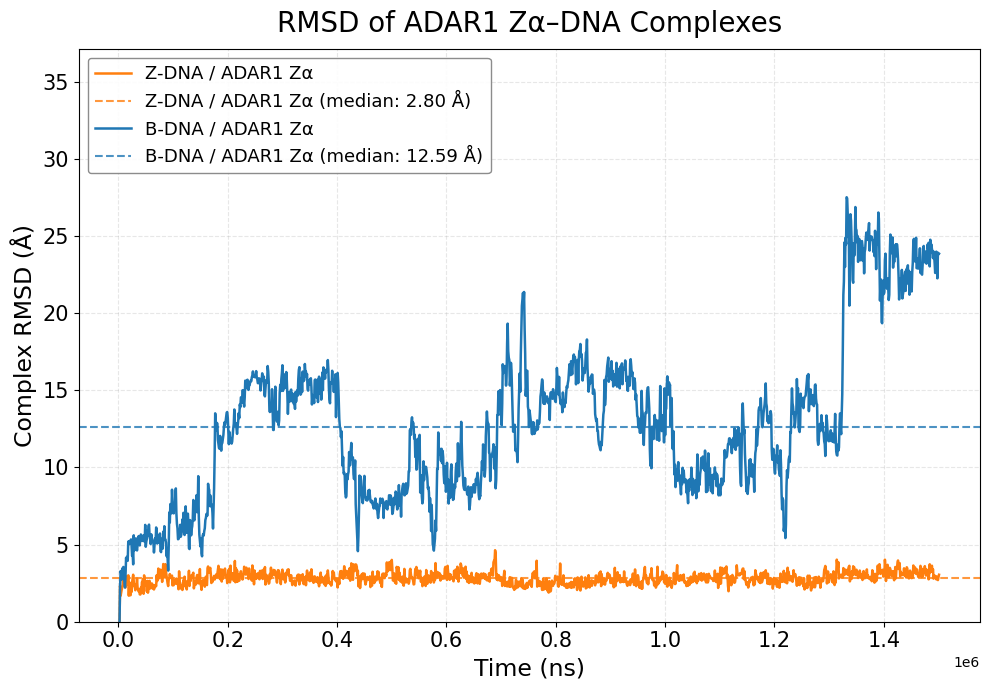

In [2]:
rmsd = {key: cached_csv(m.csv("rmsd"), lambda m=m: compute_rmsd(load_universe(m))) for key, m in MODELS.items()}

fig, ax = plt.subplots(figsize=(10, 7))
for key, df in rmsd.items():
    m, median = MODELS[key], df["rmsd"].median()
    ax.plot(df["time_ps"] * config.RMSD_TIME_FACTOR, df["rmsd"], label=m.label, color=m.color, linewidth=1.8)
    ax.axhline(median, color=m.color, linestyle="--", linewidth=1.5, alpha=0.8, label=f"{m.label} (median: {median:.2f} Å)")
ax.set_xlabel("Time (ns)", fontsize=17)
ax.set_ylabel("Complex RMSD (Å)", fontsize=17)
ax.set_title("RMSD of ADAR1 Zα–DNA Complexes", fontsize=20, pad=12)
ax.tick_params(axis="both", labelsize=15)
ax.grid(alpha=0.3, linestyle="--")
ax.set_ylim(0, max(df["rmsd"].max() for df in rmsd.values()) * 1.35)
ax.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="gray", fontsize=13, loc="upper left", ncol=1)
fig.tight_layout()
save_figure(fig, "RMSD_plot_Z_DNA_B_DNA_ADAR1")
plt.show()

### RMSF Analysis

INFO: The attribute(s) masses, types have already been read from the topology file. The guesser will only guess empty values for this attribute, if any exists. To overwrite it by completely guessed values, you can pass the attribute to the force_guess parameter instead of the to_guess one
INFO: There is no empty types values. Guesser did not guess any new values for types attribute
INFO: There is no empty masses values. Guesser did not guess any new values for masses attribute
INFO: Choosing frames to analyze
INFO: Starting preparation
INFO: Finishing up
INFO: Saved /home/bulat/Рабочий стол/Article_draft_MDS/zalpha_md_analysis/output/csv/ZDNA_ADAR1_Zalpha_RMSF.csv
INFO: The attribute(s) masses, types have already been read from the topology file. The guesser will only guess empty values for this attribute, if any exists. To overwrite it by completely guessed values, you can pass the attribute to the force_guess parameter instead of the to_guess one
INFO: There is no empty types values.

Saved: RMSF_plot_ADAR1_Zalpha_DNA_models.png


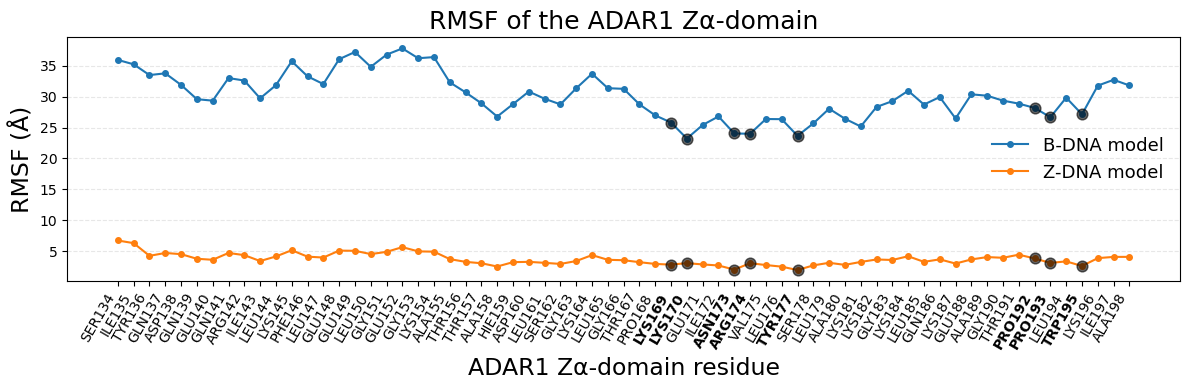

In [ ]:
rmsf = {key: cached_csv(m.csv("rmsf"), lambda m=m: compute_rmsf(load_universe(m))) for key, m in MODELS.items()}
rmsf_order = ["B-DNA", "Z-DNA"]  # legend order; residue names on the x axis are taken from the first model
shared = set.intersection(*(set(rmsf[key]["resid"]) for key in rmsf_order))
rmsf = {key: rmsf[key][rmsf[key]["resid"].isin(shared)].reset_index(drop=True) for key in rmsf_order}
ref = rmsf[rmsf_order[0]]
x = np.arange(len(ref))
labels = [f"{name}{resid + config.RESIDUE_NUMBERING_OFFSET}" for name, resid in zip(ref["resname"], ref["resid"])]
is_key = ref["resid"].isin(config.LITERATURE_RESIDUES).to_numpy()  # literature key residues

fig, ax = plt.subplots(figsize=(12, 4))
for key in rmsf_order:
    ax.plot(x, rmsf[key]["rmsf"], marker="o", markersize=4, linewidth=1.5, color=MODELS[key].color, label=MODELS[key].short_label)
for key in rmsf_order:
    ax.scatter(x[is_key], rmsf[key]["rmsf"][is_key], s=60, zorder=5, color="black", alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=10)
highlight_tick_labels(ax.get_xticklabels(), set(np.array(labels)[is_key]))
ax.set_xlabel("ADAR1 Zα-domain residue", fontsize=17)
ax.set_ylabel("RMSF (Å)", fontsize=17)
ax.set_title("RMSF of the ADAR1 Zα-domain", fontsize=18)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.tick_params(axis="y", labelsize=10)
ax.legend(fontsize=13, frameon=False)
fig.tight_layout()
save_figure(fig, "RMSF_plot_ADAR1_Zalpha_DNA_models")
plt.show()

### Contact profile between DNA group atoms and protein and their lifespan

In [4]:
contacts = {key: run_contact_and_lifetime_analysis(m) for key, m in MODELS.items()}  # computed once, then read from output/csv

INFO: Reading cached ZDNA_ADAR1_Zalpha_Interaction_Analysis_4A.csv
INFO: Reading cached ZDNA_ADAR1_Zalpha_contact_lifetimes.csv
INFO: Reading cached ZDNA_ADAR1_Zalpha_residue_lifetimes.csv
INFO: Reading cached BDNA_ADAR1_Zalpha_Interaction_Analysis_4A.csv
INFO: Reading cached BDNA_ADAR1_Zalpha_contact_lifetimes.csv
INFO: Reading cached BDNA_ADAR1_Zalpha_residue_lifetimes.csv


Saved: combined_contact_heatmaps_Z-B-DNA_A4.png, combined_contact_heatmaps_Z-B-DNA_A4.pdf


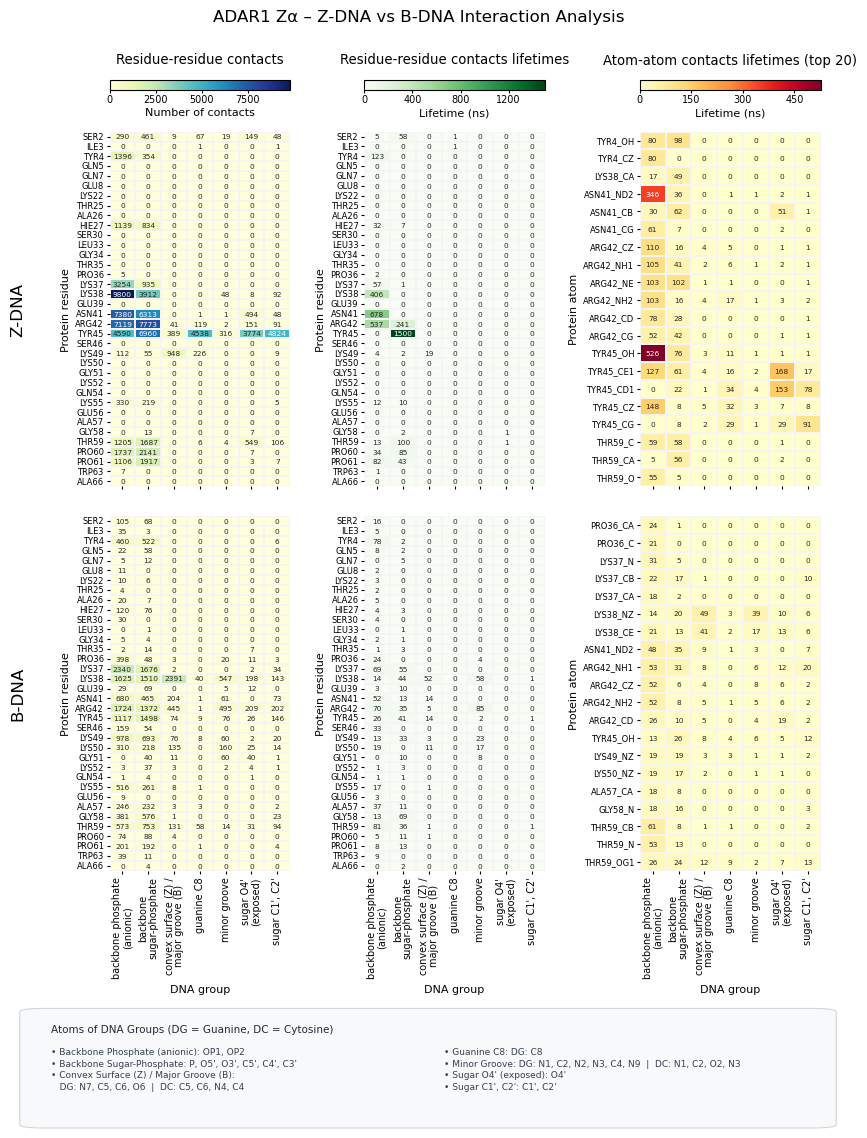

In [ ]:
# Page geometry and font sizes
A4_W, A4_H = 8.27, 11.69
LEFT_MARGIN, RIGHT_MARGIN, BOTTOM_MARGIN = 0.30, 0.12, 0.25
YZONE = [0.74, 0.74, 0.95]
TOP_SUPTITLE, TOP_HEADINGS, TOP_CBAR, CBAR_H, TOP_HEATMAPS = 0.35, 0.78, 0.98, 0.10, 1.50
ROW_GAP, XLABEL_ZONE, FOOTER_BOX_H = 0.30, 1.30, 1.25
FONT_SUPTITLE, FONT_HEADING, FONT_ROW_LABEL, FONT_CBAR = 12, 9.5, 12, 7
FONT_Y_MAX, FONT_Y_MIN, FONT_ANNOT_MAX = 8.0, 5.5, 7.0

rect = lambda left, bottom, width, height: [left / A4_W, bottom / A4_H, width / A4_W, height / A4_H]
row_bottom_B = BOTTOM_MARGIN + FOOTER_BOX_H + XLABEL_ZONE
panel_h = (A4_H - TOP_HEATMAPS - row_bottom_B - ROW_GAP) / 2
row_bottom = {"Z-DNA": row_bottom_B + panel_h + ROW_GAP, "B-DNA": row_bottom_B}
panel_w = (A4_W - LEFT_MARGIN - RIGHT_MARGIN - sum(YZONE)) / 3
panel_left, x = [], LEFT_MARGIN
for yz in YZONE:
    panel_left.append(x := x + yz)
    x += panel_w

# Columns: heading, colormap, colour-bar label, float values, y label, matrices for Z and B
data = {key: (MODELS[key].dna_type, contacts[key]) for key in ["Z-DNA", "B-DNA"]}
res_contacts = {key: residue_contact_matrix(c["contacts"], t) for key, (t, c) in data.items()}
res_lifetimes = {key: residue_lifetime_matrix(c["residue_lifetimes"], t) for key, (t, c) in data.items()}
atom_lifetimes = {key: atom_lifetime_matrix(c["atom_lifetimes"], t) for key, (t, c) in data.items()}
aligned = align_residues(res_contacts["Z-DNA"], res_lifetimes["Z-DNA"], res_contacts["B-DNA"], res_lifetimes["B-DNA"])
res_contacts["Z-DNA"], res_lifetimes["Z-DNA"], res_contacts["B-DNA"], res_lifetimes["B-DNA"] = aligned
columns = [("Residue-residue contacts", "YlGnBu", "Number of contacts", False, "Protein residue", res_contacts),
           ("Residue-residue contacts lifetimes", "Greens", "Lifetime (ns)", True, "Protein residue", res_lifetimes),
           (f"Atom-atom contacts lifetimes (top {config.TOP_N_ATOMS})", "YlOrRd", "Lifetime (ns)", True, "Protein atom", atom_lifetimes)]

# Shared font sizes fitted to the densest panel
max_rows = max(m.shape[0] for col in columns for m in col[5].values())
pitch_pt, cell_w_pt = panel_h * 72 / max_rows, panel_w * 72 / len(dna_group_order("Z-DNA"))
max_len = max(len(s) for col in columns for m in col[5].values() for s in heatmap_annotations(m, col[3]).ravel())
FS_Y = float(np.clip(pitch_pt * 0.85, FONT_Y_MIN, FONT_Y_MAX))
FS_ANNOT = min(FONT_ANNOT_MAX, pitch_pt * 0.75, cell_w_pt / (0.62 * max_len + 0.5))

fig = plt.figure(figsize=(A4_W, A4_H))
for c, (heading, cmap, cbar_label, is_float, ylabel, matrices) in enumerate(columns):
    vmax = max(m.values.max() for m in matrices.values())
    norm = colors.Normalize(vmin=0, vmax=vmax if vmax > 0 else 1)
    for key, m in matrices.items():
        ax = fig.add_axes(rect(panel_left[c], row_bottom[key], panel_w, panel_h))
        draw_heatmap(ax, m, cmap, norm, is_float, ylabel, key == "B-DNA", FS_Y, FS_ANNOT, panel_h)
    draw_colorbar(fig, fig.add_axes(rect(panel_left[c], A4_H - TOP_CBAR - CBAR_H, panel_w, CBAR_H)), cmap, norm, cbar_label, not is_float, FONT_CBAR)
    fig.text((panel_left[c] + panel_w / 2) / A4_W, (A4_H - TOP_HEADINGS) / A4_H, heading, fontsize=FONT_HEADING, ha="center", va="center")

fig.suptitle("ADAR1 Zα – Z-DNA vs B-DNA Interaction Analysis", fontsize=FONT_SUPTITLE, y=(A4_H - TOP_SUPTITLE) / A4_H, va="center")
for key, bottom in row_bottom.items():
    fig.text(0.12 / A4_W, (bottom + panel_h / 2) / A4_H, key, fontsize=FONT_ROW_LABEL, rotation=90, va="center", ha="center")
draw_dna_group_legend(fig.add_axes(rect(LEFT_MARGIN, BOTTOM_MARGIN, A4_W - LEFT_MARGIN - RIGHT_MARGIN, FOOTER_BOX_H - 0.1)))
save_figure(fig, "combined_contact_heatmaps_Z-B-DNA_A4", formats=("png", "pdf"), dpi=600, tight=False)
plt.show()

### Co-occurrence of Zalpha residues contacts with DNA

Saved: ADAR1_Z-DNA_Jaccard_Analysis.png


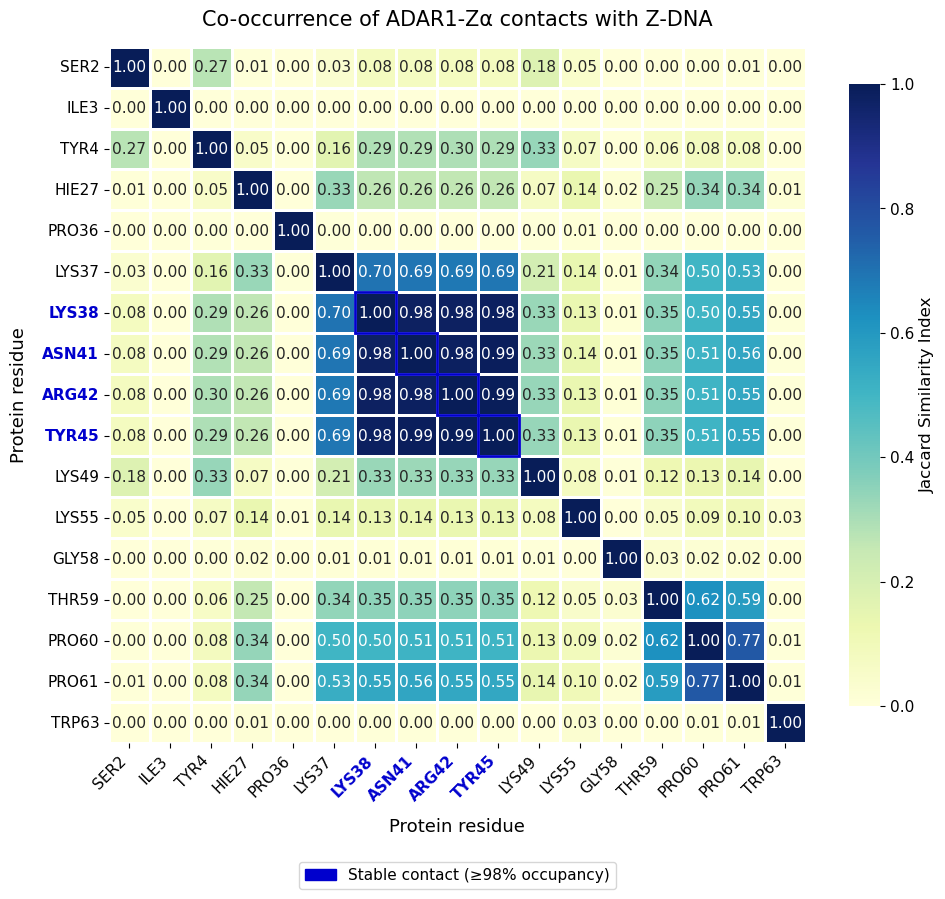

Saved: ADAR1_B-DNA_Jaccard_Analysis.png


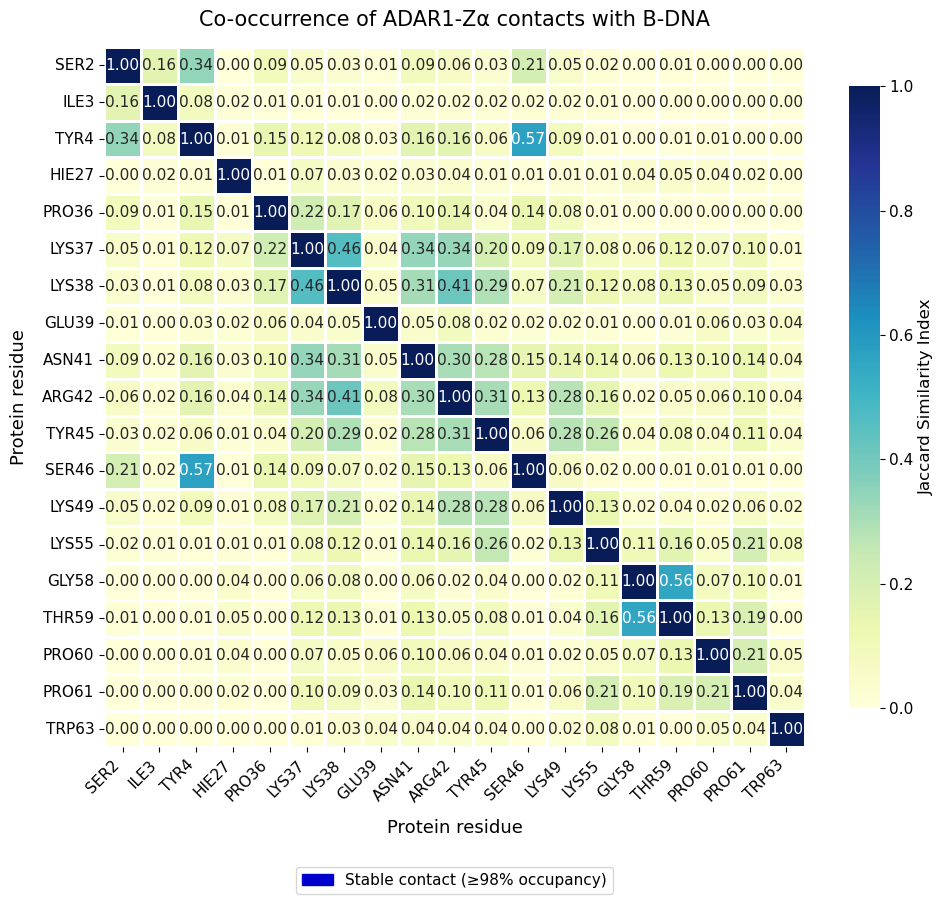

In [6]:
for key in MODELS:
    similarity, stable_residues = contact_cooccurrence(contacts[key]["contacts"])
    fig = plot_jaccard_heatmap(similarity, stable_residues, dna_label=key)
    save_figure(fig, f"ADAR1_{key}_Jaccard_Analysis")
    plt.show()

### Interaction energies (FoldX/PyRosetta)

In [4]:
RUN_FOLDX, RUN_PYROSETTA = True, True
if RUN_FOLDX:
    foldx_energies = {key: run_foldx_analysis(m) for key, m in MODELS.items()}
if RUN_PYROSETTA:
    rosetta_energies = {key: run_interface_analysis(m) for key, m in MODELS.items()}

INFO: Reading cached ZDNA_ADAR1_Zalpha_FoldX_interaction_energy.csv
INFO: Reading cached BDNA_ADAR1_Zalpha_FoldX_interaction_energy.csv
INFO: Reading cached ZDNA_ADAR1_Zalpha_Rosetta_interface_dG.csv
INFO: Reading cached BDNA_ADAR1_Zalpha_Rosetta_interface_dG.csv


Saved: FoldX_interaction_energy_Z_DNA_B_DNA_ADAR1.png


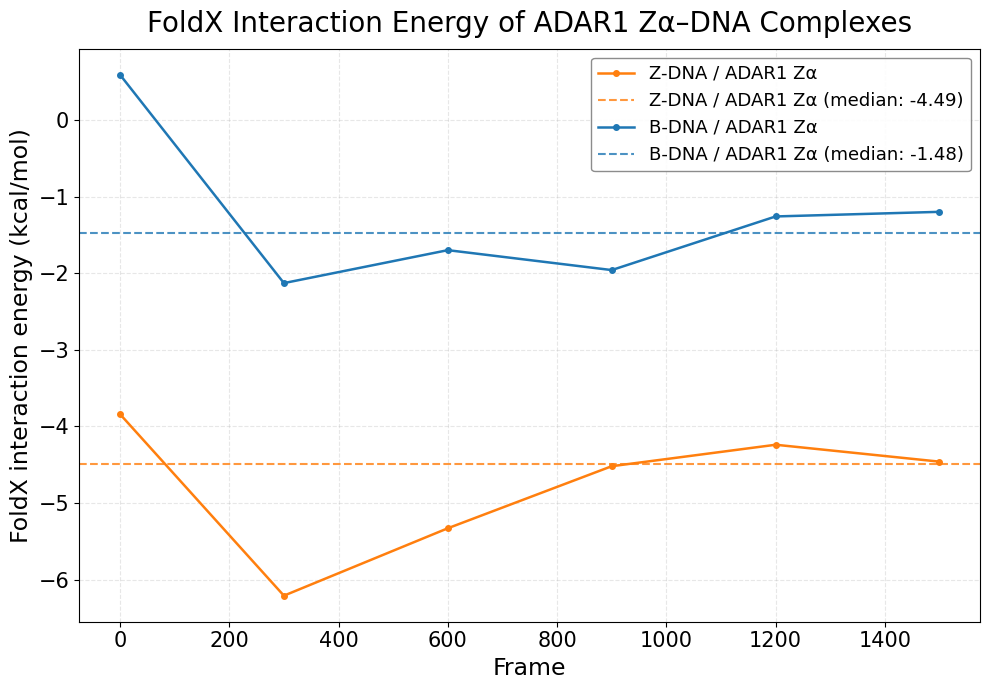

Saved: Rosetta_interface_dG_Z_DNA_B_DNA_ADAR1.png


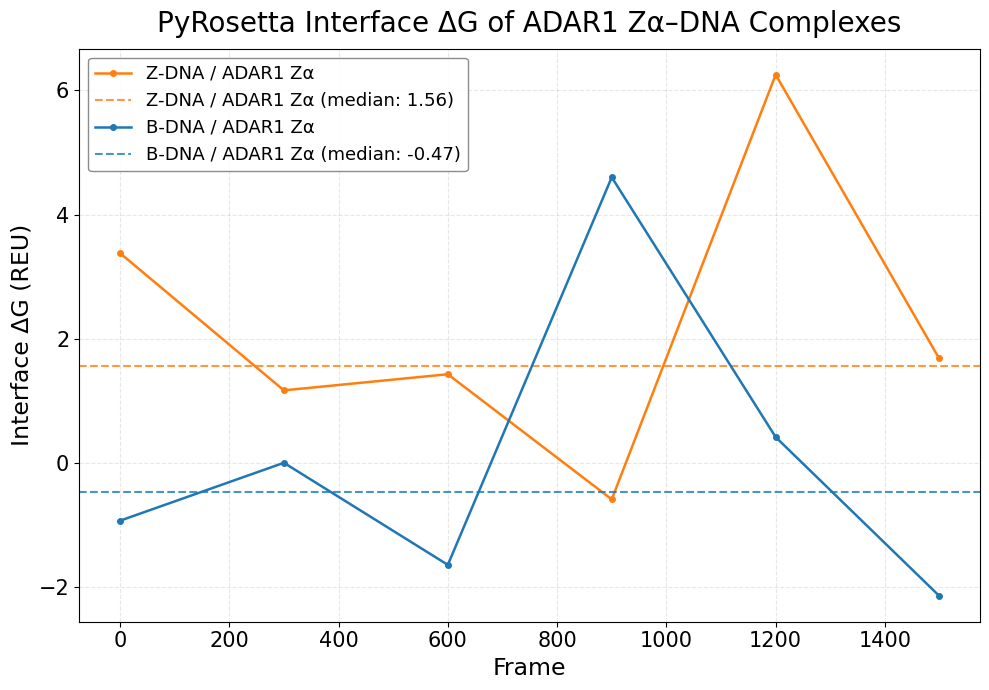

In [ ]:
energy_plots = [  # data, column, y label, title, file name
    (globals().get("foldx_energies"), "InteractionEnergy_kcal", "FoldX interaction energy (kcal/mol)", "FoldX Interaction Energy", "FoldX_interaction_energy"),
    (globals().get("rosetta_energies"), "ΔG_interface_REU", "Interface ΔG (REU)", "PyRosetta Interface ΔG", "Rosetta_interface_dG"),
]
for energies, column, ylabel, title, name in energy_plots:
    if energies is None:  # method was not run (RUN_FOLDX / RUN_PYROSETTA = False)
        continue
    fig, ax = plt.subplots(figsize=(10, 7))
    for key, df in energies.items():
        m, median = MODELS[key], df[column].median()
        ax.plot(df["frame"], df[column], marker="o", markersize=4, label=m.label, color=m.color, linewidth=1.8)
        ax.axhline(median, color=m.color, linestyle="--", linewidth=1.5, alpha=0.8, label=f"{m.label} (median: {median:.2f})")
    ax.set_xlabel("Frame", fontsize=17)
    ax.set_ylabel(ylabel, fontsize=17)
    ax.set_title(f"{title} of ADAR1 Zα–DNA Complexes", fontsize=20, pad=12)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(alpha=0.3, linestyle="--")
    ax.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="gray", fontsize=13, loc="best")
    fig.tight_layout()
    save_figure(fig, f"{name}_Z_DNA_B_DNA_ADAR1")
    plt.show()